In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Data Cleaning And Manipulation

In [2]:
df=pd.read_csv('Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [5]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
for col in df.select_dtypes(include='object').columns:
    print(col ,':',df[col].unique())

customerID : ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
gender : ['Female' 'Male']
Partner : ['Yes' 'No']
Dependents : ['No' 'Yes']
PhoneService : ['No' 'Yes']
MultipleLines : ['No phone service' 'No' 'Yes']
InternetService : ['DSL' 'Fiber optic' 'No']
OnlineSecurity : ['No' 'Yes' 'No internet service']
OnlineBackup : ['Yes' 'No' 'No internet service']
DeviceProtection : ['No' 'Yes' 'No internet service']
TechSupport : ['No' 'Yes' 'No internet service']
StreamingTV : ['No' 'Yes' 'No internet service']
StreamingMovies : ['No' 'Yes' 'No internet service']
Contract : ['Month-to-month' 'One year' 'Two year']
PaperlessBilling : ['Yes' 'No']
PaymentMethod : ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
TotalCharges : ['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
Churn : ['No' 'Yes']


In [9]:
## CostomerId is wont provide any such help in pediction it is related to unique idetntifier assigned to each customer 

In [10]:
df.drop(columns='customerID',inplace=True)

In [11]:
## TOtal Charges is assigned as string we will convert its datatype as float

In [12]:
df['TotalCharges']=df.TotalCharges.replace('',np.nan)

In [13]:
df['TotalCharges']=df.TotalCharges.replace(' ',np.nan)

In [14]:
df['TotalCharges']=df.TotalCharges.astype('float')

In [15]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [16]:
df.dropna(inplace=True)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 
 17  

In [18]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.162400,32.421786,64.798208,2283.300441
std,0.368844,24.545260,30.085974,2266.771362
min,0.000000,1.000000,18.250000,18.800000
25%,0.000000,9.000000,35.587500,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.862500,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [19]:
df.describe(include='object')

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032
unique,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,3549,3639,4933,6352,3385,3096,3497,3087,3094,3472,2809,2781,3875,4168,2365,5163


## Visualization

* Univariate

In [20]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

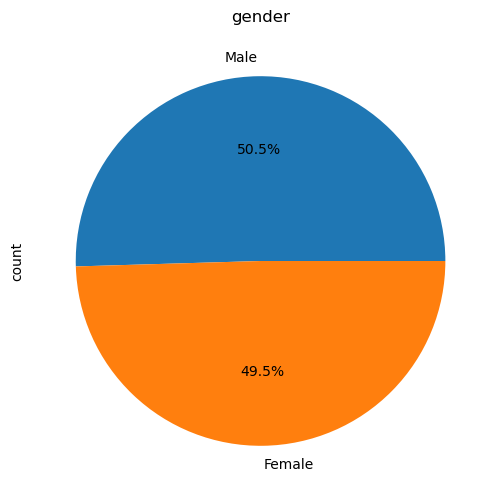

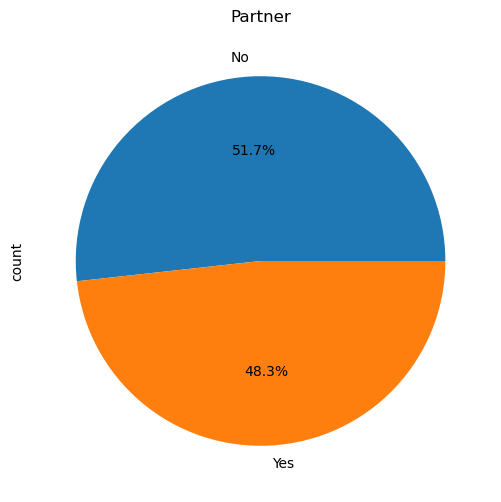

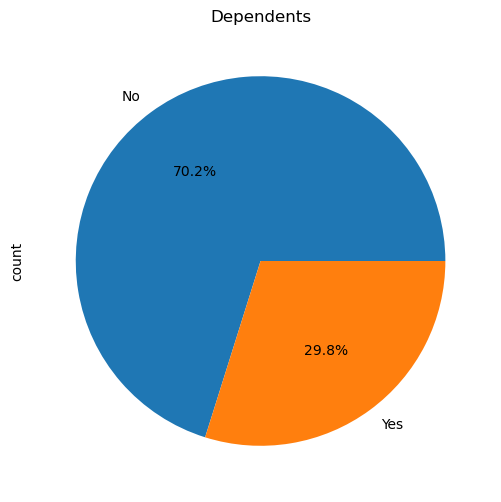

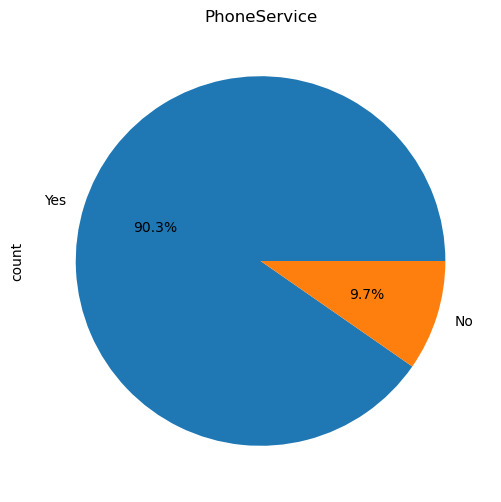

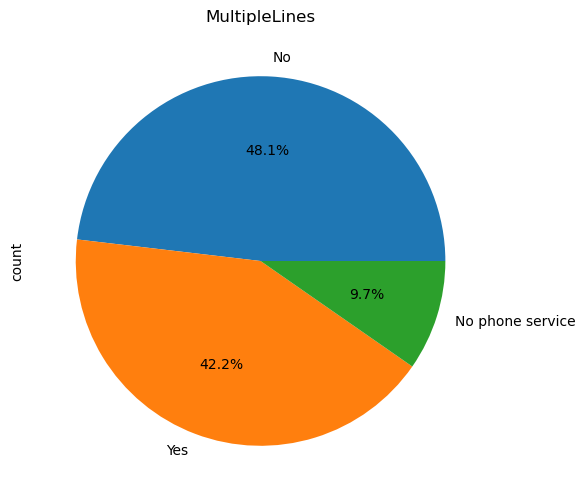

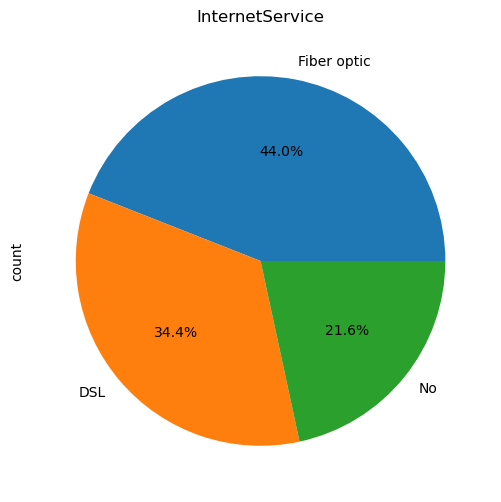

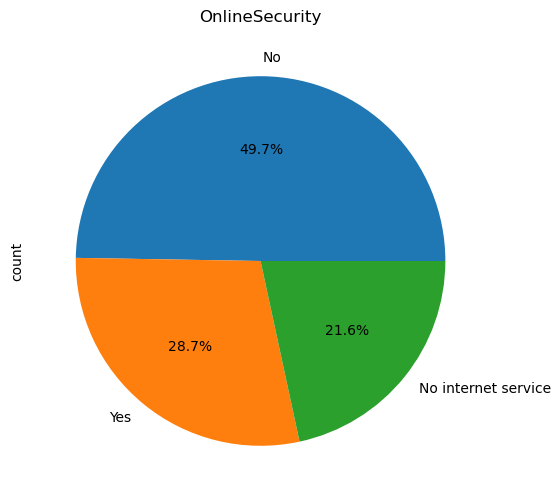

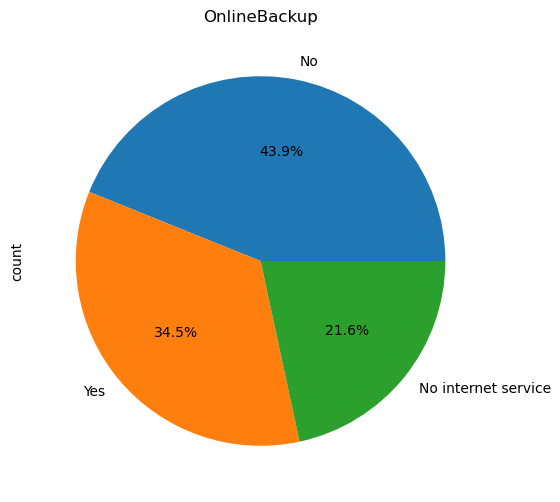

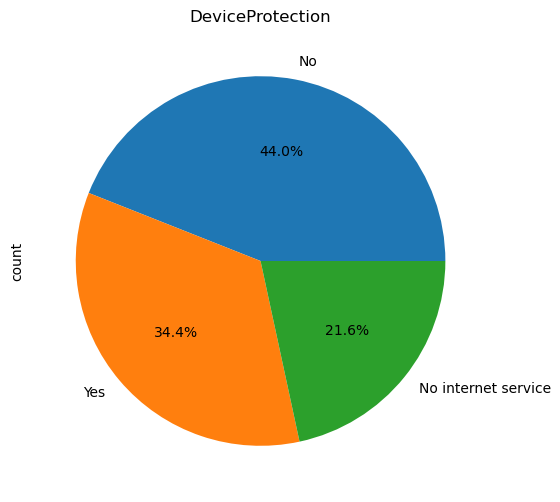

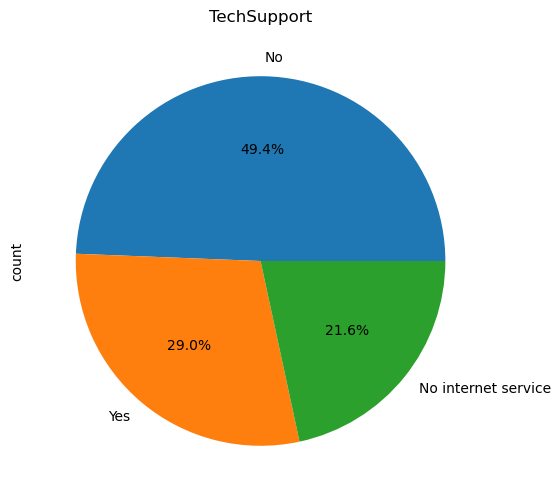

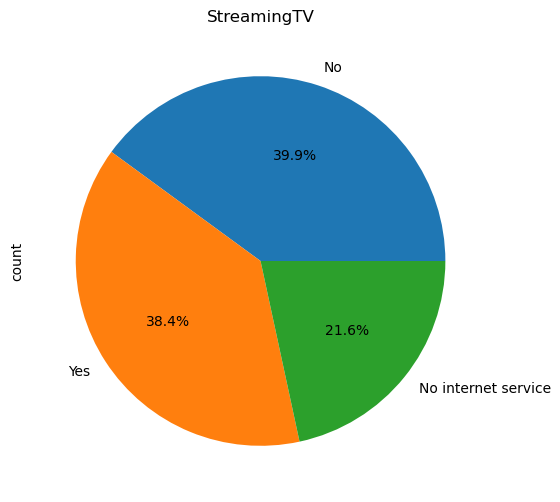

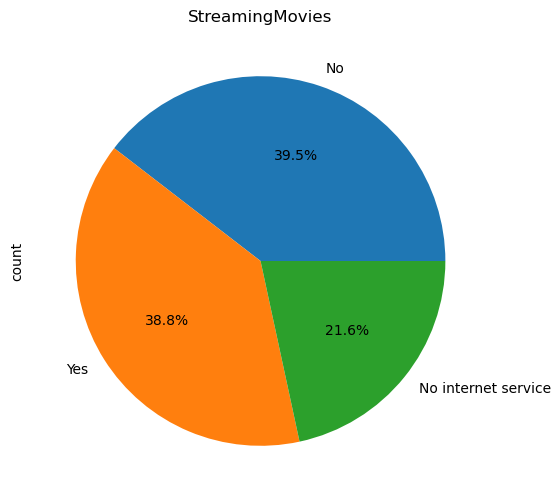

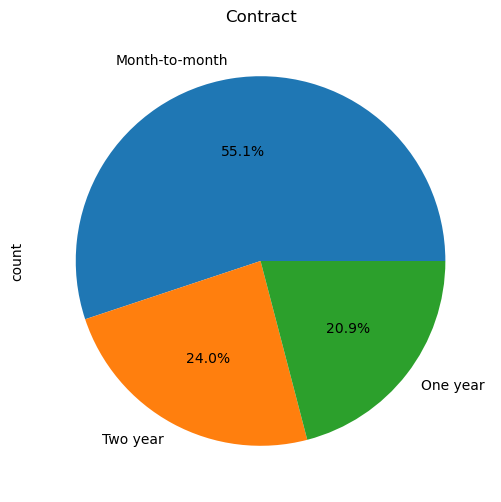

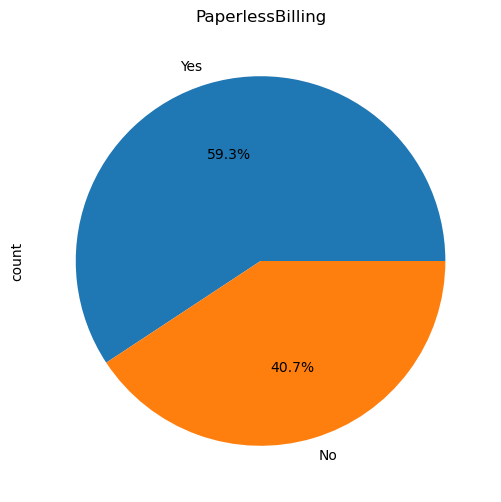

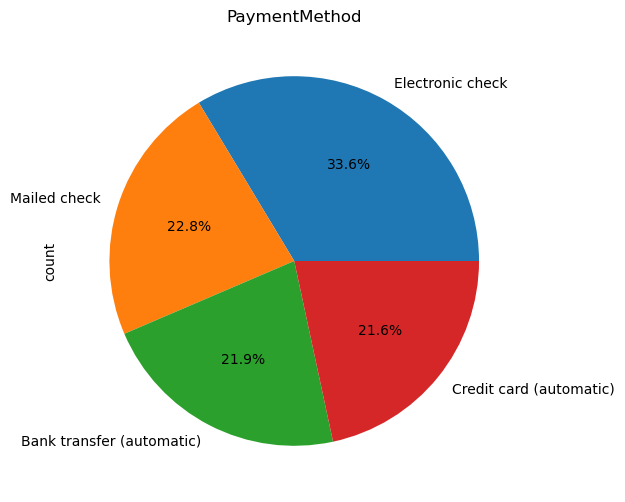

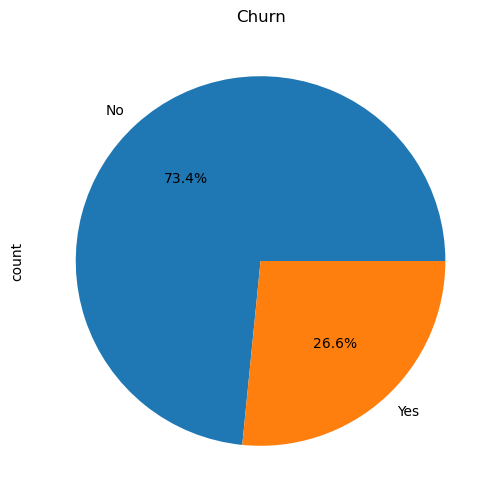

In [21]:
for col in df.select_dtypes(include='object').columns:
    plt.figure(figsize=(10,6))
    df[col].value_counts().plot(kind='pie',autopct='%1.1f%%')
    plt.title(col)
    plt.show()

In [22]:
df.select_dtypes(include=['int','float']).columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

<Axes: xlabel='SeniorCitizen', ylabel='count'>

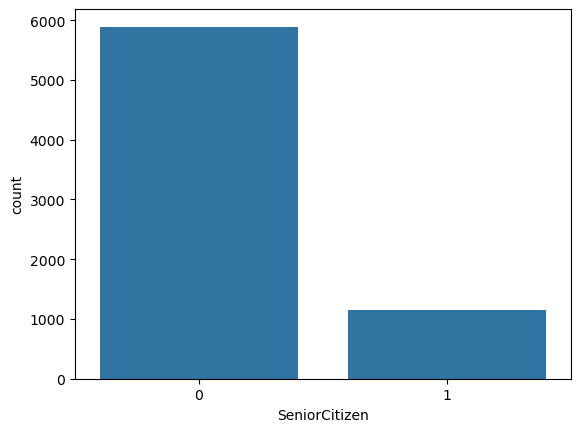

In [23]:
sns.countplot(x=df['SeniorCitizen'])

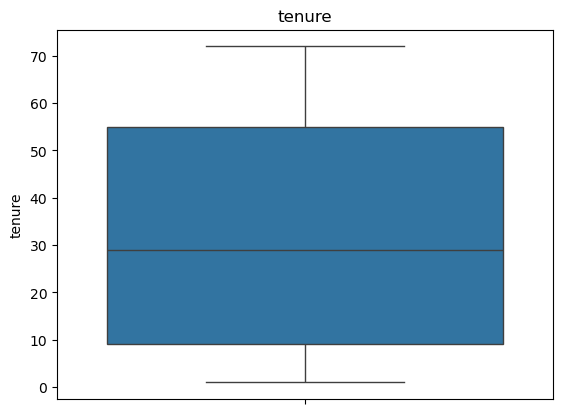

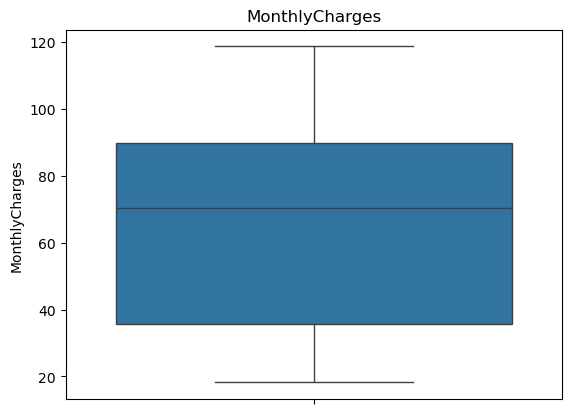

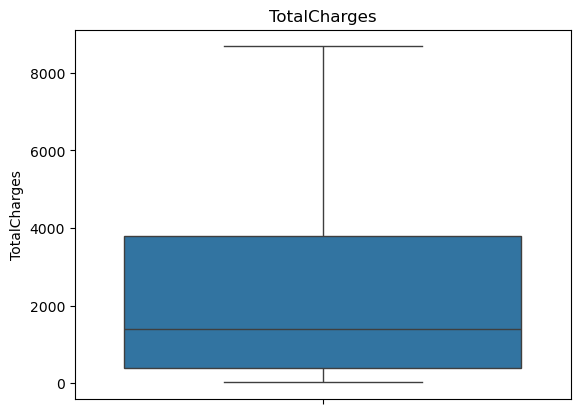

In [24]:
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    sns.boxplot(y=df[col])
    plt.title(col)
    plt.show()

* Bivariate

* Target Vs Feature
`Target = 'churn'`
`Features = 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'`

<Axes: xlabel='SeniorCitizen', ylabel='count'>

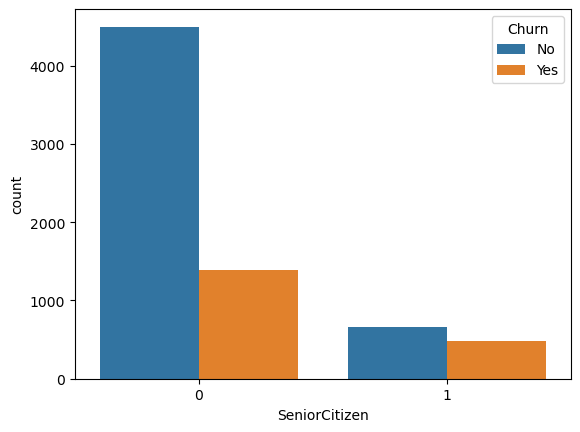

In [25]:
sns.countplot(x=df['SeniorCitizen'],hue=df['Churn'])

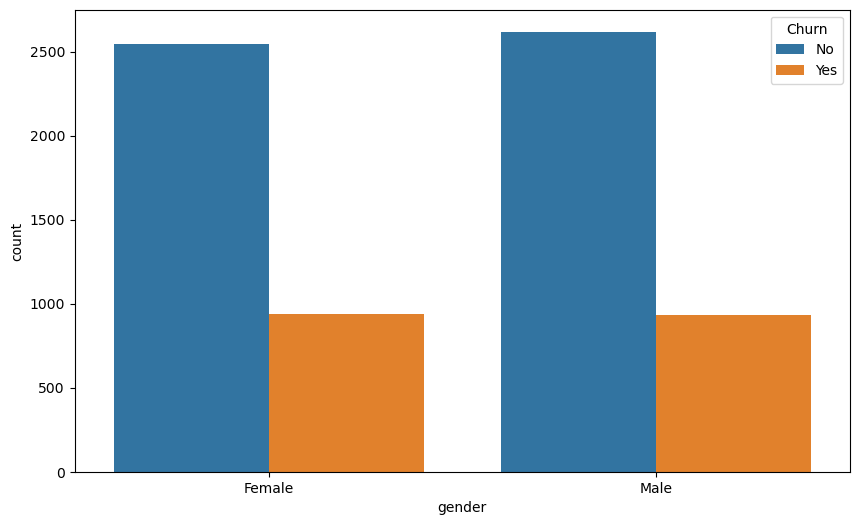

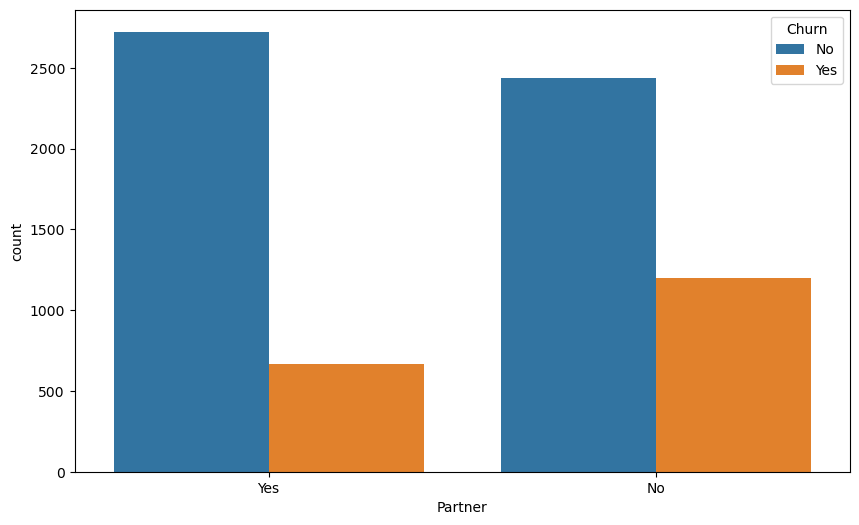

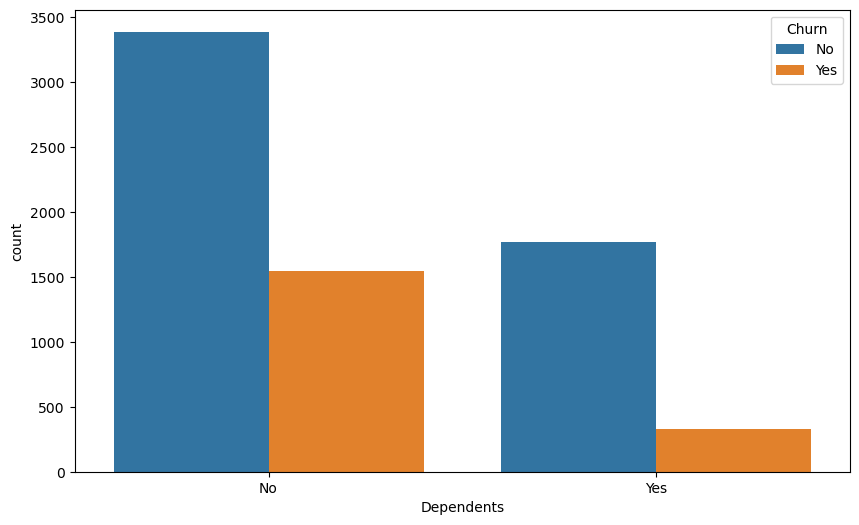

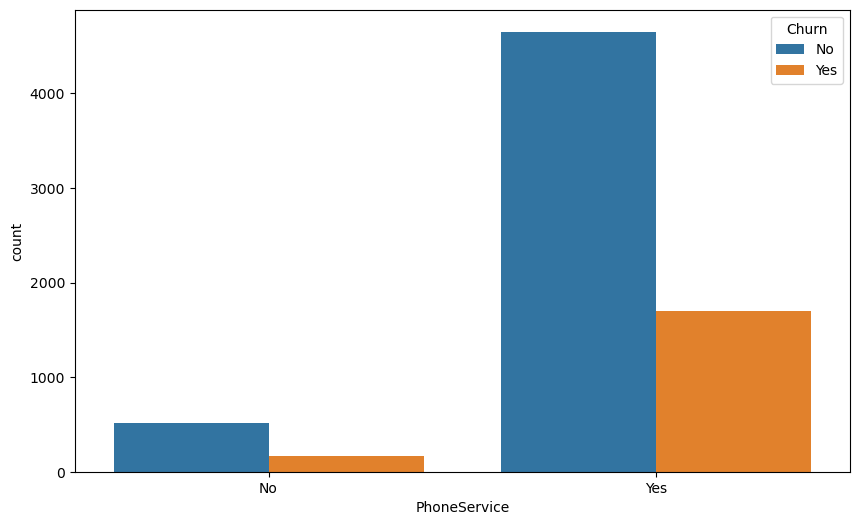

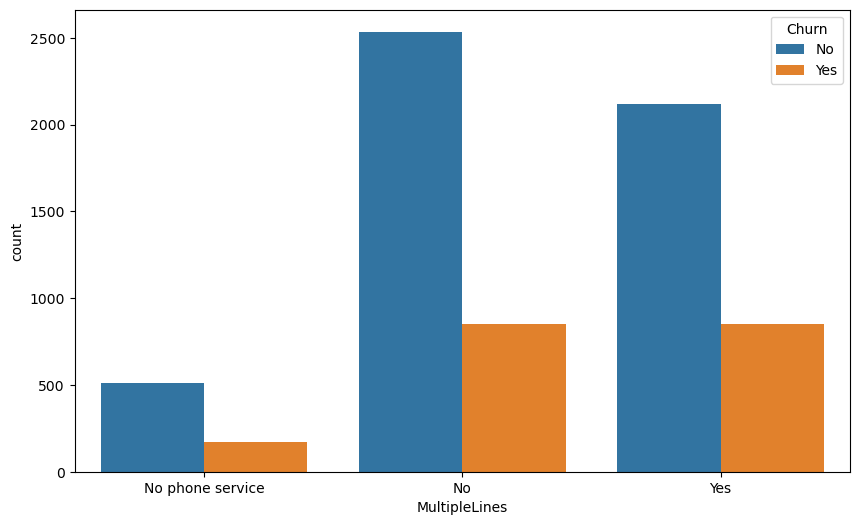

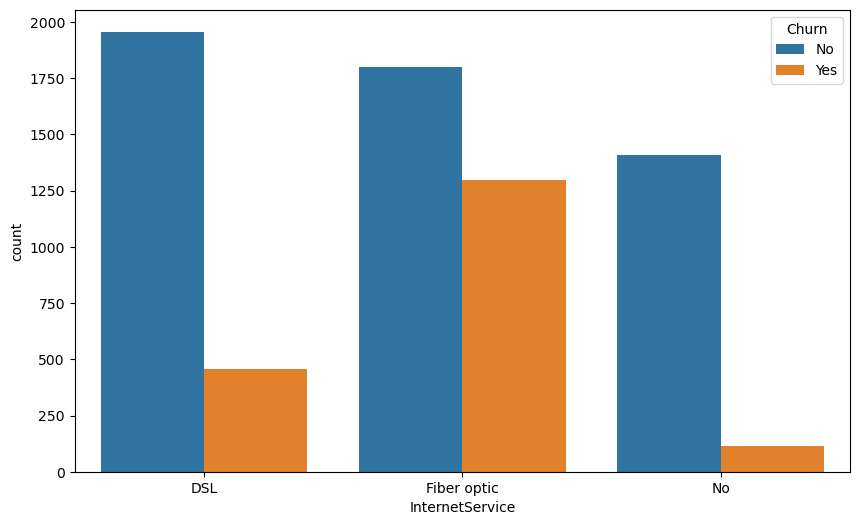

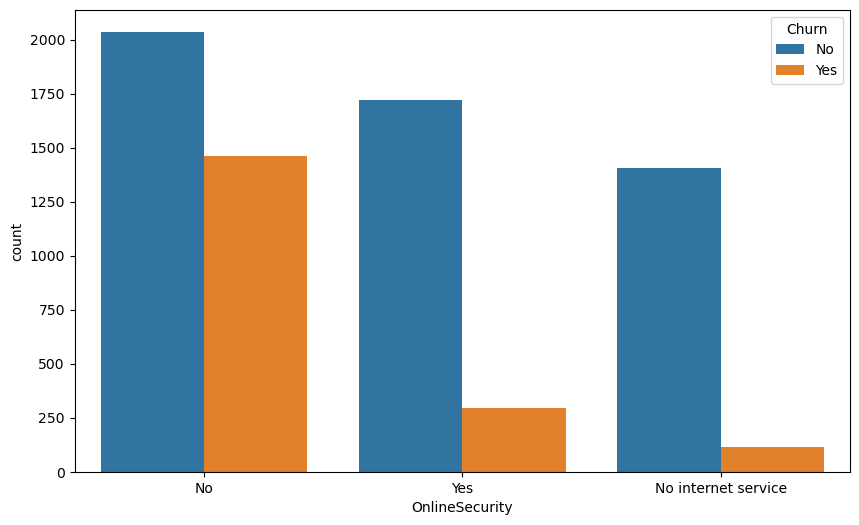

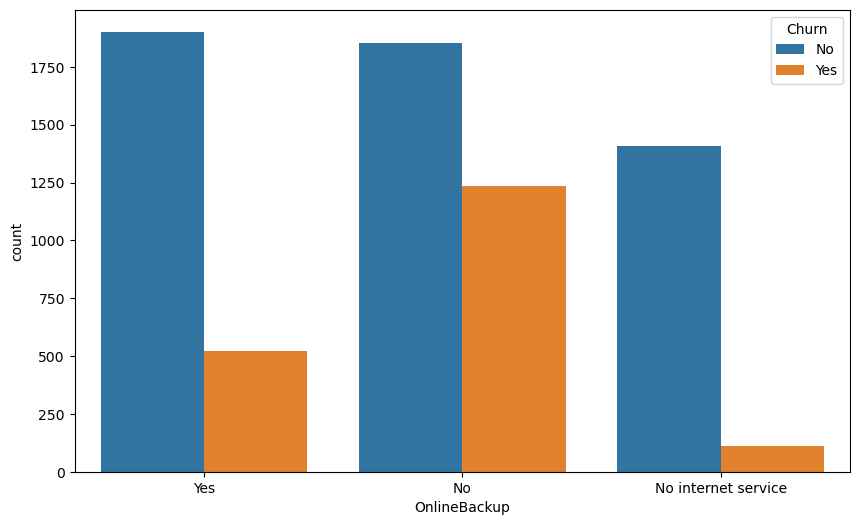

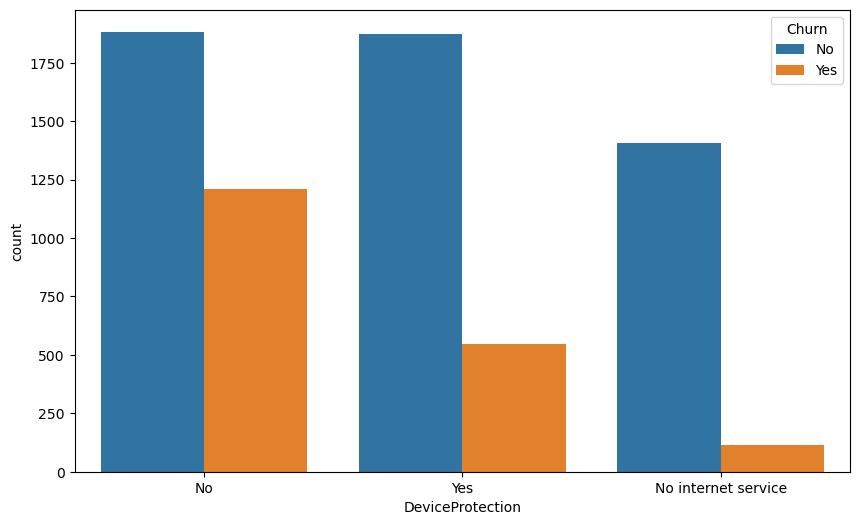

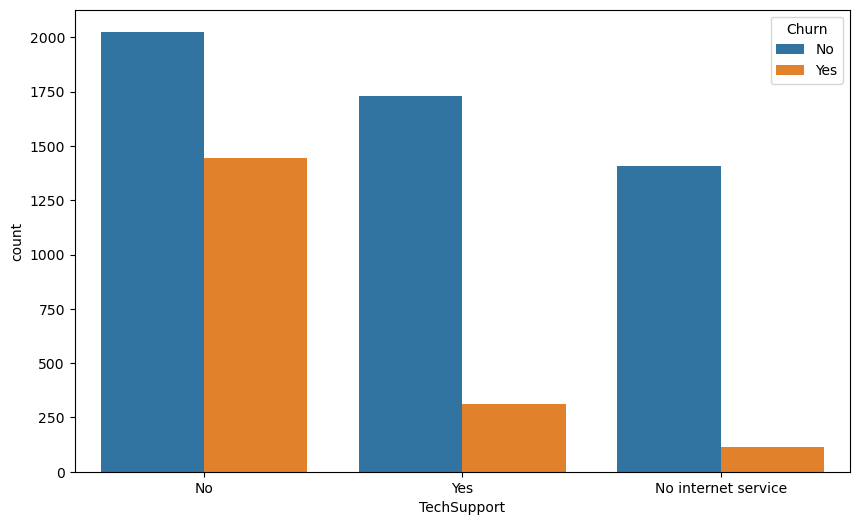

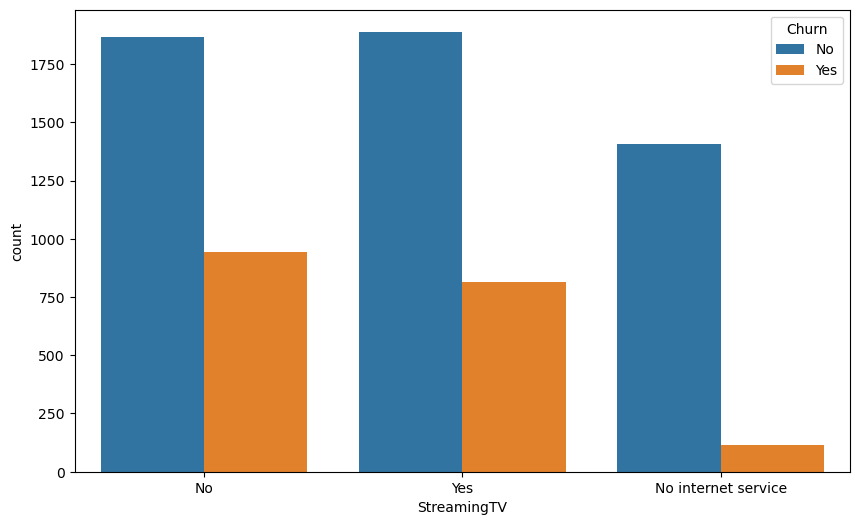

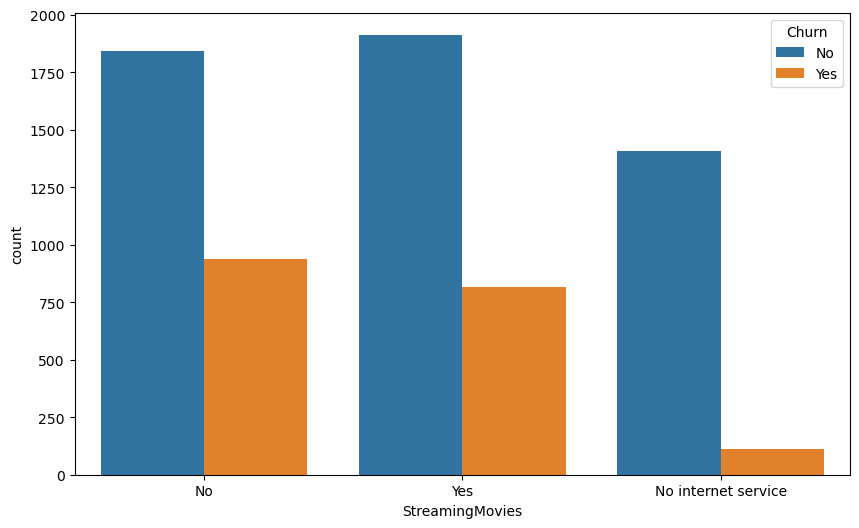

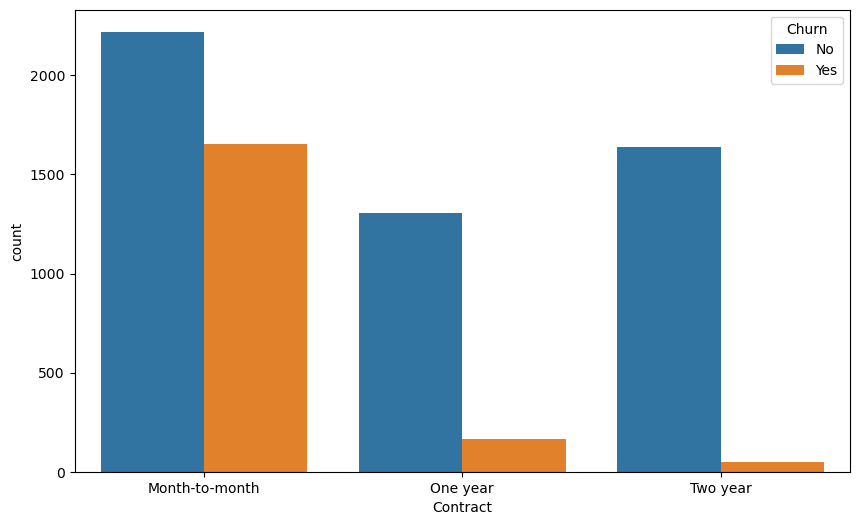

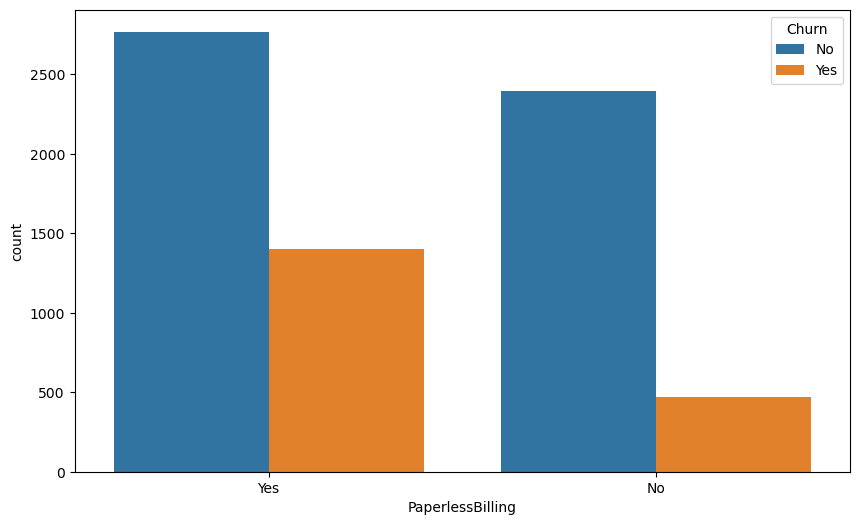

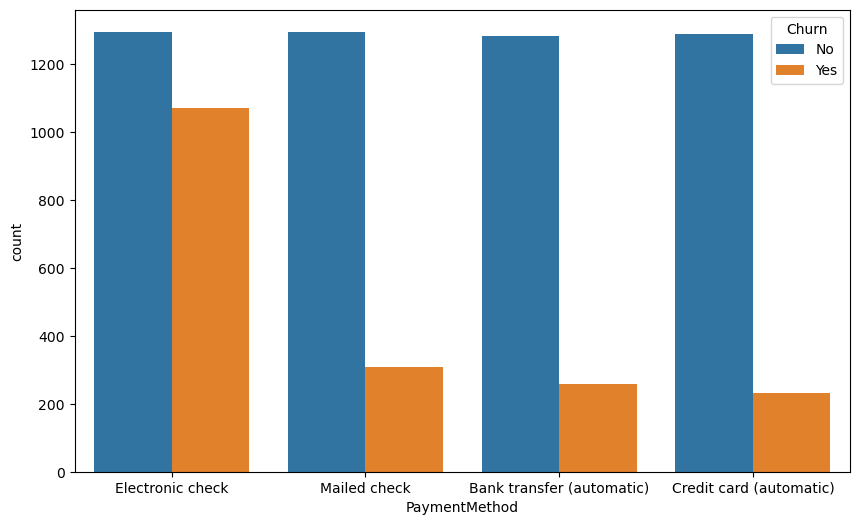

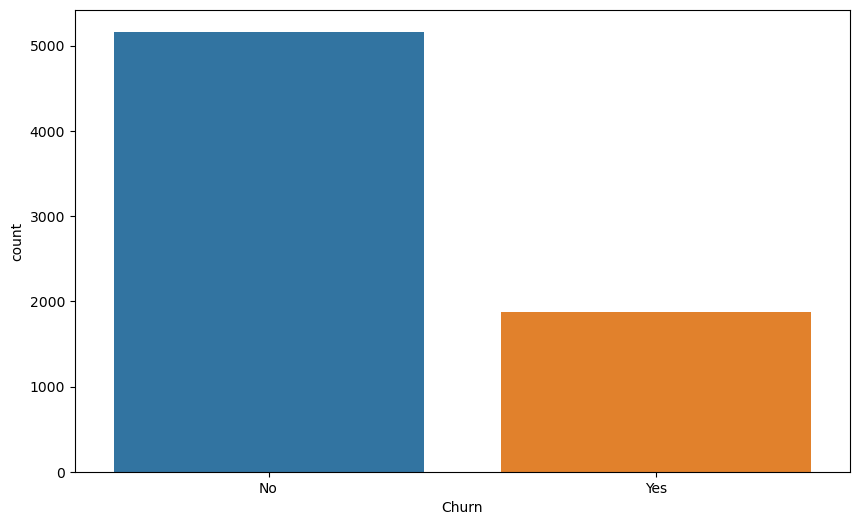

In [26]:
for col in df.select_dtypes(include='object').columns:
    plt.figure(figsize=(10,6))
    sns.countplot(x=df[col],hue=df['Churn'])

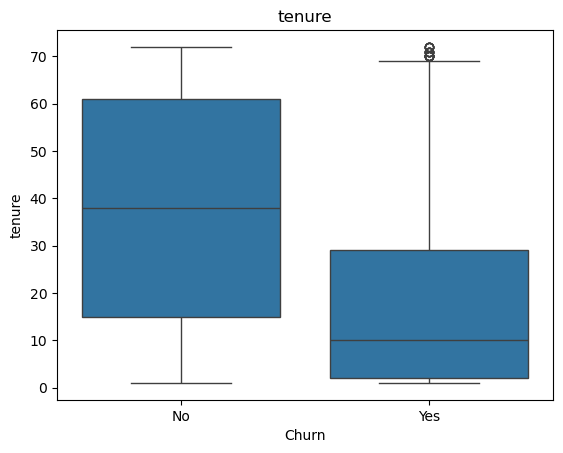

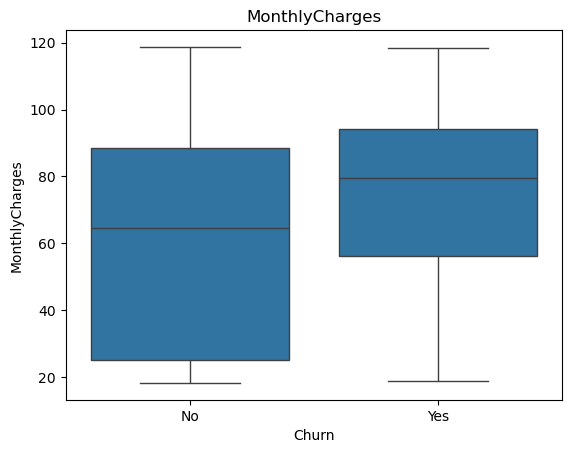

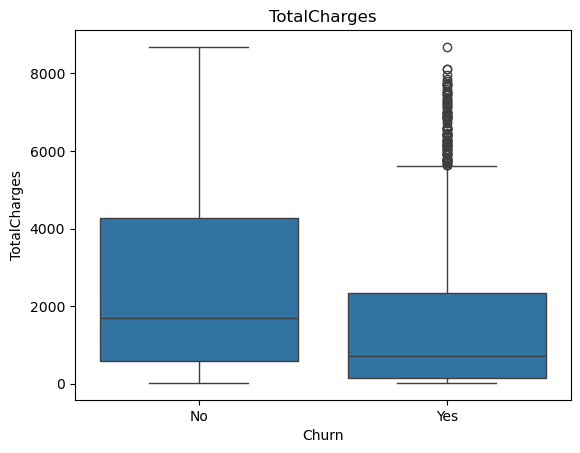

In [27]:
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    sns.boxplot(y=df[col],x=df['Churn'])
    plt.title(col)
    plt.show()

In [28]:
df.to_csv('cleanedtele.csv',index=False)

In [29]:
df=pd.read_csv('cleanedtele.csv')
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7028,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7029,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7030,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [30]:
features=['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges']
target='Churn'

# Train Test And Split

In [31]:
## As this is classification we will perform encoding and scaling after train_test_split 

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
train_df,test_df=train_test_split(df,test_size=0.2,random_state=42)

In [34]:
x_train=train_df[features]
x_test=test_df[features]
y_train=train_df[target]
y_test=test_df[target]

In [35]:
print('Shape of Train DF',x_train.shape,y_train.shape)
print('Shape of Test DF',x_test.shape,y_test.shape)


Shape of Train DF (5625, 19) (5625,)
Shape of Test DF (1407, 19) (1407,)


## Encoding

In [36]:
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

In [37]:
x_train=x_train.copy()
x_test=x_test.copy()
y_train=y_train.copy()
y_test=y_test.copy()

In [38]:
x_train.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

In [39]:

gender_le=LabelEncoder()
partner_le=LabelEncoder()
dep_le=LabelEncoder()
ph_le=LabelEncoder()
ins_le=LabelEncoder()
pb_le=LabelEncoder()
pm_le=LabelEncoder()
churn_le=LabelEncoder()

In [40]:
# Gender
x_train['gender'] = gender_le.fit_transform(x_train['gender'])
x_test['gender'] = gender_le.transform(x_test['gender'])

# Partner
x_train['Partner'] = partner_le.fit_transform(x_train['Partner'])
x_test['Partner'] = partner_le.transform(x_test['Partner'])

# Dependents
x_train['Dependents'] = dep_le.fit_transform(x_train['Dependents'])
x_test['Dependents'] = dep_le.transform(x_test['Dependents'])

# Phone Service
x_train['PhoneService'] = ph_le.fit_transform(x_train['PhoneService'])
x_test['PhoneService'] = ph_le.transform(x_test['PhoneService'])

# Internet Service
x_train['InternetService'] = ins_le.fit_transform(x_train['InternetService'])
x_test['InternetService'] = ins_le.transform(x_test['InternetService'])

# Paperless Billing
x_train['PaperlessBilling'] = pb_le.fit_transform(x_train['PaperlessBilling'])
x_test['PaperlessBilling'] = pb_le.transform(x_test['PaperlessBilling'])

# Payment Method
x_train['PaymentMethod'] = pm_le.fit_transform(x_train['PaymentMethod'])
x_test['PaymentMethod'] = pm_le.transform(x_test['PaymentMethod'])

# Target
y_train = churn_le.fit_transform(y_train)
y_test = churn_le.transform(y_test)

In [41]:
# MultipleLines
x_train['MultipleLines'] = x_train['MultipleLines'].replace({
    'No phone service': 0,
    'No': 0,
    'Yes': 1
})

x_test['MultipleLines'] = x_test['MultipleLines'].replace({
    'No phone service': 0,
    'No': 0,
    'Yes': 1
})
# OnlineSecurity
x_train['OnlineSecurity'] = x_train['OnlineSecurity'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})

x_test['OnlineSecurity'] = x_test['OnlineSecurity'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})
# OnlineBackup
x_train['OnlineBackup'] = x_train['OnlineBackup'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})

x_test['OnlineBackup'] = x_test['OnlineBackup'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})
# DeviceProtection
x_train['DeviceProtection'] = x_train['DeviceProtection'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})

x_test['DeviceProtection'] = x_test['DeviceProtection'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})
# TechSupport
x_train['TechSupport'] = x_train['TechSupport'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})

x_test['TechSupport'] = x_test['TechSupport'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})
# StreamingTV
x_train['StreamingTV'] = x_train['StreamingTV'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})

x_test['StreamingTV'] = x_test['StreamingTV'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})
# StreamingMovies
x_train['StreamingMovies'] = x_train['StreamingMovies'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})

x_test['StreamingMovies'] = x_test['StreamingMovies'].replace({
    'No internet service': 0,
    'No': 0,
    'Yes': 1
})

C:\Users\nisht\AppData\Local\Temp\ipykernel_27872\4145852668.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x_train['MultipleLines'] = x_train['MultipleLines'].replace({
C:\Users\nisht\AppData\Local\Temp\ipykernel_27872\4145852668.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x_test['MultipleLines'] = x_test['MultipleLines'].replace({
C:\Users\nisht\AppData\Local\Temp\ipykernel_27872\4145852668.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the ol

In [42]:
## Contract
x_train['Contract']=x_train['Contract'].replace({'Month-to-month':0 ,'One year':1, 'Two year':2})
x_test['Contract']=x_test['Contract'].replace({'Month-to-month':0 ,'One year':1, 'Two year':2})


C:\Users\nisht\AppData\Local\Temp\ipykernel_27872\691047283.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x_train['Contract']=x_train['Contract'].replace({'Month-to-month':0 ,'One year':1, 'Two year':2})
C:\Users\nisht\AppData\Local\Temp\ipykernel_27872\691047283.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x_test['Contract']=x_test['Contract'].replace({'Month-to-month':0 ,'One year':1, 'Two year':2})


In [43]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

In [44]:
'''num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

x_train[num_cols] = sc.fit_transform(x_train[num_cols])
x_test[num_cols] = sc.transform(x_test[num_cols])'''

"num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']\n\nx_train[num_cols] = sc.fit_transform(x_train[num_cols])\nx_test[num_cols] = sc.transform(x_test[num_cols])"

In [45]:
x_train.reset_index(drop=True)

x_test.reset_index(drop=True)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,1,1,1,0,0.845070,1,1,2,0,0,0,0,0,0,2,0,0,0.067164,0.171118
1,0,0,0,0,0.253521,1,1,2,0,0,0,0,0,0,0,0,0,0.064179,0.051581
2,1,0,1,0,0.169014,1,1,1,0,0,1,0,1,1,0,1,1,0.835821,0.154645
3,1,0,1,0,0.507042,1,1,0,1,0,0,0,0,0,0,1,3,0.366169,0.232162
4,0,0,0,0,0.070423,0,0,0,1,0,0,0,0,0,0,0,0,0.111443,0.016455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1402,1,0,0,0,0.000000,1,0,2,0,0,0,0,0,0,0,0,3,0.007960,0.000023
1403,1,0,0,0,0.154930,1,1,1,0,0,0,0,1,1,0,0,2,0.759204,0.133246
1404,0,0,0,0,0.352113,1,0,0,0,1,1,0,0,0,1,1,3,0.376119,0.177055
1405,0,1,0,0,0.478873,1,1,1,1,1,1,1,1,1,1,1,0,0.920896,0.440511


In [46]:
## ClASS IMBALANCE 
from imblearn.over_sampling import SMOTE

smote=SMOTE(random_state=42)
x_train_smote,y_train_smote=smote.fit_resample(x_train,y_train)



In [47]:

pd.Series(y_train_smote).value_counts()

1    4130
0    4130
Name: count, dtype: int64

## Model Training

## Logistic Regression

In [48]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()

In [49]:
lr.fit(x_train_smote,y_train_smote)

LogisticRegression()

In [50]:
from sklearn.metrics import classification_report,confusion_matrix

In [51]:
y_pred=lr.predict(x_train_smote)


In [52]:
print(classification_report(y_train_smote,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.75      0.78      4130
           1       0.77      0.82      0.80      4130

    accuracy                           0.79      8260
   macro avg       0.79      0.79      0.79      8260
weighted avg       0.79      0.79      0.79      8260



In [53]:
y_pred_lr=lr.predict(x_test)
print(classification_report(y_test,y_pred_lr))


              precision    recall  f1-score   support

           0       0.90      0.73      0.80      1033
           1       0.50      0.76      0.61       374

    accuracy                           0.74      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.74      0.75      1407



In [54]:
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score

y_prob = lr.predict_proba(x_test)[:, 1]

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    print(
        f"Threshold={threshold:.2f} | "
        f"Accuracy={accuracy_score(y_test, y_pred):.3f} | "
        f"Precision={precision_score(y_test, y_pred):.3f} | "
        f"Recall={recall_score(y_test, y_pred):.3f} | "
        f"F1={f1_score(y_test, y_pred):.3f}")

Threshold=0.30 | Accuracy=0.657 | Precision=0.431 | Recall=0.909 | F1=0.585
Threshold=0.35 | Accuracy=0.677 | Precision=0.444 | Recall=0.866 | F1=0.587
Threshold=0.40 | Accuracy=0.701 | Precision=0.465 | Recall=0.842 | F1=0.599
Threshold=0.45 | Accuracy=0.723 | Precision=0.487 | Recall=0.802 | F1=0.606
Threshold=0.50 | Accuracy=0.737 | Precision=0.504 | Recall=0.765 | F1=0.607
Threshold=0.55 | Accuracy=0.751 | Precision=0.522 | Recall=0.725 | F1=0.607
Threshold=0.60 | Accuracy=0.763 | Precision=0.544 | Recall=0.679 | F1=0.604


# Random Forest Clf

In [55]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(x_train_smote, y_train_smote)

RandomForestClassifier(n_estimators=200, random_state=42)

In [56]:
y_pred_rf = rf.predict(x_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.85      0.81      0.83      1033
           1       0.54      0.61      0.57       374

    accuracy                           0.76      1407
   macro avg       0.70      0.71      0.70      1407
weighted avg       0.77      0.76      0.76      1407



In [57]:
y_prob = rf.predict_proba(x_test)[:, 1]

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    print(
        f"Threshold={threshold:.2f} | "
        f"Accuracy={accuracy_score(y_test, y_pred):.3f} | "
        f"Precision={precision_score(y_test, y_pred):.3f} | "
        f"Recall={recall_score(y_test, y_pred):.3f} | "
        f"F1={f1_score(y_test, y_pred):.3f}")

Threshold=0.30 | Accuracy=0.682 | Precision=0.446 | Recall=0.824 | F1=0.579
Threshold=0.35 | Accuracy=0.710 | Precision=0.472 | Recall=0.773 | F1=0.586
Threshold=0.40 | Accuracy=0.728 | Precision=0.492 | Recall=0.725 | F1=0.586
Threshold=0.45 | Accuracy=0.746 | Precision=0.518 | Recall=0.668 | F1=0.583
Threshold=0.50 | Accuracy=0.757 | Precision=0.537 | Recall=0.620 | F1=0.576
Threshold=0.55 | Accuracy=0.765 | Precision=0.556 | Recall=0.567 | F1=0.562
Threshold=0.60 | Accuracy=0.778 | Precision=0.593 | Recall=0.529 | F1=0.559


# Xgboost clf

In [58]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)

xgb.fit(x_train_smote, y_train_smote)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [59]:
y_pred_xgb = xgb.predict(x_test)

print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.88      0.75      0.81      1033
           1       0.51      0.73      0.60       374

    accuracy                           0.74      1407
   macro avg       0.70      0.74      0.70      1407
weighted avg       0.78      0.74      0.75      1407



In [60]:
y_prob = xgb.predict_proba(x_test)[:, 1]

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    print(
        f"Threshold={threshold:.2f} | "
        f"Accuracy={accuracy_score(y_test, y_pred):.3f} | "
        f"Precision={precision_score(y_test, y_pred):.3f} | "
        f"Recall={recall_score(y_test, y_pred):.3f} | "
        f"F1={f1_score(y_test, y_pred):.3f}")

Threshold=0.30 | Accuracy=0.681 | Precision=0.448 | Recall=0.858 | F1=0.588
Threshold=0.35 | Accuracy=0.701 | Precision=0.464 | Recall=0.816 | F1=0.592
Threshold=0.40 | Accuracy=0.711 | Precision=0.474 | Recall=0.789 | F1=0.592
Threshold=0.45 | Accuracy=0.733 | Precision=0.498 | Recall=0.754 | F1=0.600
Threshold=0.50 | Accuracy=0.741 | Precision=0.509 | Recall=0.727 | F1=0.599
Threshold=0.55 | Accuracy=0.751 | Precision=0.524 | Recall=0.682 | F1=0.592
Threshold=0.60 | Accuracy=0.763 | Precision=0.545 | Recall=0.642 | F1=0.590


In [61]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.737029,0.503521,0.764706,0.607219
1,Random Forest,0.757640,0.538642,0.614973,0.574282
2,XGBoost,0.741294,0.509363,0.727273,0.599119


In [62]:
## Logistic Regression have high recall , hence it will be deployed
# as we Performed threshold earlier we will use that during deployment to increase recall, precision and f1 score of class1

<Axes: xlabel='Model', ylabel='Recall'>

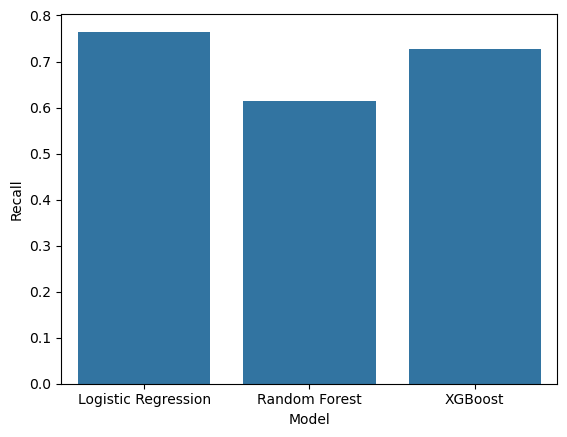

In [63]:
sns.barplot(x='Model',y='Recall',data=results)

In [64]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Coefficient': lr.coef_[0]
})

feature_importance = feature_importance.sort_values(
    by='Coefficient',
    ascending=False
)

print(feature_importance)

             Feature  Coefficient
17    MonthlyCharges     4.000522
18      TotalCharges     2.966272
15  PaperlessBilling     0.098699
16     PaymentMethod    -0.002844
1      SeniorCitizen    -0.031781
2            Partner    -0.061617
7    InternetService    -0.109117
13   StreamingMovies    -0.140272
6      MultipleLines    -0.175742
0             gender    -0.223152
12       StreamingTV    -0.263910
10  DeviceProtection    -0.402957
3         Dependents    -0.418024
9       OnlineBackup    -0.593791
14          Contract    -0.883789
11       TechSupport    -0.955769
8     OnlineSecurity    -0.961094
5       PhoneService    -1.336742
4             tenure    -3.533446


In [65]:
drop_cols = [
    'PaymentMethod',
    'SeniorCitizen',
    'Partner',
    'PaperlessBilling'
]

x_train_smote = x_train_smote.drop(columns=drop_cols)
x_test = x_test.drop(columns=drop_cols)

In [66]:
x_train_smote = x_train_smote.drop(columns=['InternetService'])
x_test = x_test.drop(columns=['InternetService'])

In [67]:
lr.fit(x_train_smote, y_train_smote)

LogisticRegression()

In [68]:
y_pred = lr.predict(x_test)

In [69]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.73      0.80      1033
           1       0.50      0.75      0.60       374

    accuracy                           0.74      1407
   macro avg       0.70      0.74      0.70      1407
weighted avg       0.79      0.74      0.75      1407



In [70]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[756 277]
 [ 94 280]]


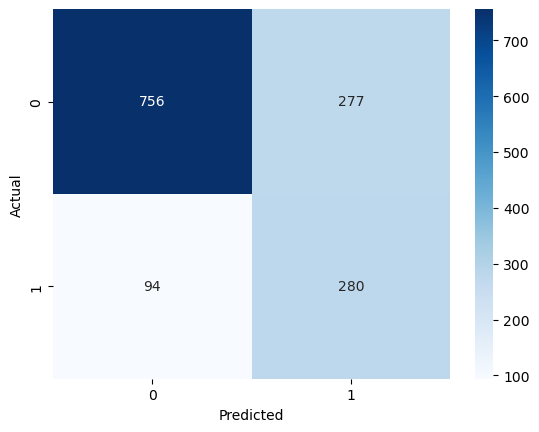

In [73]:
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [74]:
import joblib

In [75]:
joblib.dump(lr,'lr_model.pkl')

['lr_model.pkl']

In [76]:
joblib.dump(scaler,'sc.pkl')

['sc.pkl']

In [77]:
joblib.dump({'gender_le':gender_le
,'partner_le':partner_le
,'dep_le':dep_le
,'ph_le':ph_le
,'ins_le':ins_le
,'pb_le':pb_le
,'pm_le':pm_le
,'churn_le':churn_le},'encoders.pkl')

['encoders.pkl']